## Basic Augumentations

In [7]:
from PIL import Image, ImageEnhance, ImageOps
import numpy as np
import random

# Loading image
image_path = r'D:\dl\archive\valid\Car\05153.jpeg'
image = Image.open(image_path)

# Translation
def translate(image, shift_x, shift_y):
    return image.transform(image.size, Image.AFFINE, (1, 0, shift_x, 0, 1, shift_y))

# Rotation
def rotate(image, angle):
    return image.rotate(angle)

# Horizontal Flip
def flip_horizontal(image):
    return image.transpose(Image.FLIP_LEFT_RIGHT)

# Vertical Flip
def flip_vertical(image):
    return image.transpose(Image.FLIP_TOP_BOTTOM)

# Contrast adjustment
def adjust_contrast(image, factor):
    enhancer = ImageEnhance.Contrast(image)
    return enhancer.enhance(factor)

# Brightness adjustment
def adjust_brightness(image, factor):
    enhancer = ImageEnhance.Brightness(image)
    return enhancer.enhance(factor)

# Adding random noise
def add_noise(image, noise_level=0.05):
    np_image = np.array(image)
    noise = np.random.randn(*np_image.shape) * noise_level * 255
    noisy_image = np.clip(np_image + noise, 0, 255).astype(np.uint8)
    return Image.fromarray(noisy_image)

# Resizing
def resize(image, size):
    return image.resize(size)

# Example of each augmentation:
images = [
    (image, 'Original'),
    (translate(image, 50, 50), 'Translated (50, 50)'),
    (rotate(image, 45), 'Rotated (45°)'),
    (flip_horizontal(image), 'Flipped Horizontal'),
    (flip_vertical(image), 'Flipped Vertical'),
    (adjust_contrast(image, 1.5), 'Contrast Increased (1.5x)'),
    (adjust_brightness(image, 1.5), 'Brightness Increased (1.5x)'),
    (add_noise(image), 'Noisy Image'),
    (resize(image, (256, 256)), 'Resized (256x256)')
]

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (img, label) in zip(axes.flat, images):
    ax.imshow(img)
    ax.set_title(label)
    ax.axis('off')  # Hide axis

plt.tight_layout()
plt.show()

## Auto Augumentation (OWN ARCHITECTURE)

In [11]:
from PIL import Image, ImageEnhance, ImageOps
import random

class AutoAugment:
    def __init__(self):
        #base functions for augmentation
        self.func = {
            "shearX": self.shearX,
            "shearY": self.shearY,
            "translateX": self.translateX,
            "translateY": self.translateY,
            "rotate": self.rotate,
            "color": self.color,
            "posterize": self.posterize,
            "solarize": self.solarize,
            "contrast": self.contrast,
            "sharpness": self.sharpness,
            "brightness": self.brightness,
            "autocontrast": self.autocontrast,
            "equalize": self.equalize,
            "invert": self.invert
        }
        
        # List of available augmentation policies (starting with 3 random augmentations)
        self.current_policy = random.sample(self.func.keys(), 3)  # Initial policy with 3 augmentations
        self.history = []  # To track past policies and accuracies
        self.policy_weights = {aug: 1.0 for aug in self.func.keys()}

    def shearX(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0.0, 0.1, 0.2, 0.3]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return img.transform(
            img.size, Image.AFFINE, (1, magnitude, 0, 0, 1, 0),
            Image.BICUBIC, fillcolor=(128, 128, 128)
        )

    def shearY(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0.0, 0.1, 0.2, 0.3]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return img.transform(
            img.size, Image.AFFINE, (1, 0, 0, magnitude, 1, 0),
            Image.BICUBIC, fillcolor=(128, 128, 128)
        )

    def translateX(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0, 20, 40, 60, 80]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return img.transform(
            img.size, Image.AFFINE, (1, 0, magnitude, 0, 1, 0),
            fillcolor=(128, 128, 128)
        )

    def translateY(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0, 20, 40, 60, 80]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return img.transform(
            img.size, Image.AFFINE, (1, 0, 0, 0, 1, magnitude),
            fillcolor=(128, 128, 128)
        )

    def rotate(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0, 15, 30, 45]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return img.rotate(magnitude)

    def color(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0.0, 0.2, 0.4, 0.6, 0.8]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return ImageEnhance.Color(img).enhance(1 + magnitude)

    def posterize(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [8, 7, 6, 5, 4]
            magnitude = random.choice(magnitude_range)
        return ImageOps.posterize(img, magnitude)

    def solarize(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0, 64, 128, 192, 256]
            magnitude = random.choice(magnitude_range)
        return ImageOps.solarize(img, magnitude)

    def contrast(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0.0, 0.2, 0.4, 0.6, 0.8]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return ImageEnhance.Contrast(img).enhance(1 + magnitude)

    def sharpness(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0.0, 0.2, 0.4, 0.6, 0.8]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return ImageEnhance.Sharpness(img).enhance(1 + magnitude)

    def brightness(self, img, magnitude = None):
        if magnitude is None:
            magnitude_range = [0.0, 0.2, 0.4, 0.6, 0.8]
            magnitude = random.choice(magnitude_range) * random.choice([-1, 1])
        return ImageEnhance.Brightness(img).enhance(1 + magnitude)

    def autocontrast(self, img):
        return ImageOps.autocontrast(img)

    def equalize(self, img):
        return ImageOps.equalize(img)

    def invert(self, img):
        return ImageOps.invert(img)

    def apply_augmentation(self, img):
            for aug in self.current_policy:
                img = self.func[aug](img)
            return img

    def apply_augmentations_to_set(self, image_set):
        augmented_set = []
        for img in image_set:
            augmented_set.append(self.apply_augmentation(img))
        return augmented_set

    def update_policy(self, current_accuracy):
        if len(self.history) > 0:
            last_accuracy = self.history[-1]["accuracy"]
            if current_accuracy > last_accuracy:
                # Increasing weights for current augmentations if accuracy improves
                for aug in self.current_policy:
                     # Rewarding better performing augmentations
                    self.policy_weights[aug] += 0.1 
            else:
                # Penalize if the accuracy drops
                for aug in self.current_policy:
                    self.policy_weights[aug] = max(0.1, self.policy_weights[aug] - 0.1)
            
            # New policy based on weights
            weights = [self.policy_weights[aug] for aug in list(self.func.keys())]
            self.current_policy = random.choices(list(self.func.keys()), weights=weights, k=3)
    
        # history
        self.history.append({"policy": self.current_policy.copy(), "accuracy": current_accuracy})

    def auto_augment(self, image_set, accuracy):
        self.update_policy(accuracy)
        augmented_images = self.apply_augmentations_to_set(image_set)
        return augmented_images

In [14]:
def display_augmented_images(augmented_set, epoch):
    """Display augmented images in a grid using plt.imshow()."""
    num_images = len(augmented_set)
    cols = 3  # Number of images per row
    rows = (num_images // cols) + (num_images % cols > 0)  # Calculate rows based on number of images

    fig, axes = plt.subplots(rows, cols, figsize=(10, 10))
    fig.suptitle(f'Epoch {epoch+1} Augmented Images', fontsize=16)

    for idx, aug_img in enumerate(augmented_set):
        ax = axes[idx // cols, idx % cols]  # Get the subplot for the image
        ax.imshow(aug_img)
        ax.axis('off')  # Hide the axes for a cleaner look
        ax.set_title(f"Image {idx+1}")

    # Hide any extra subplots that might exist if the number of images isn't a multiple of the grid size
    for ax in axes.flatten()[num_images:]:
        ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to include the title
    plt.show()

C:\Users\M LAKSHMI NARASIMHA\AppData\Local\Temp\ipykernel_10852\1370216277.py:25: DeprecationWarning: Sampling from a set deprecated
since Python 3.9 and will be removed in a subsequent version.
  self.current_policy = random.sample(self.func.keys(), 3)  # Initial policy with 3 augmentations


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

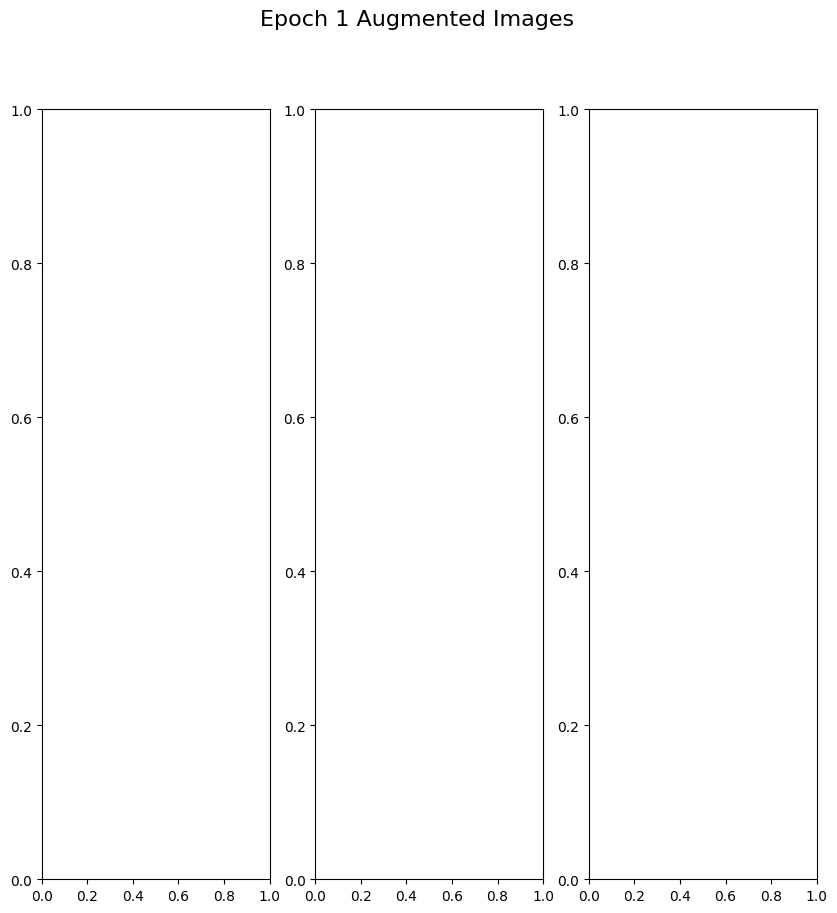

In [15]:
# Example images
image_paths = [r'archive\valid\Car\10158.jpeg', r'archive\valid\Car\10164.jpeg', r'archive\valid\Car\10151.jpeg']
image_set = [Image.open(path) for path in image_paths]

auto_augmenter = AutoAugment()

# Simulation of training loop
for epoch in range(10):
    accuracy = random.uniform(0.7, 1.0)
    augmented_set = auto_augmenter.auto_augment(image_set, accuracy)

    display_augmented_images(augmented_set, epoch)

    print(f"Epoch {epoch+1}, Accuracy: {accuracy:.2f}, Policy: {auto_augmenter.current_policy}")

C:\Users\M LAKSHMI NARASIMHA\AppData\Local\Temp\ipykernel_10852\1370216277.py:25: DeprecationWarning: Sampling from a set deprecated
since Python 3.9 and will be removed in a subsequent version.
  self.current_policy = random.sample(self.func.keys(), 3)  # Initial policy with 3 augmentations


IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

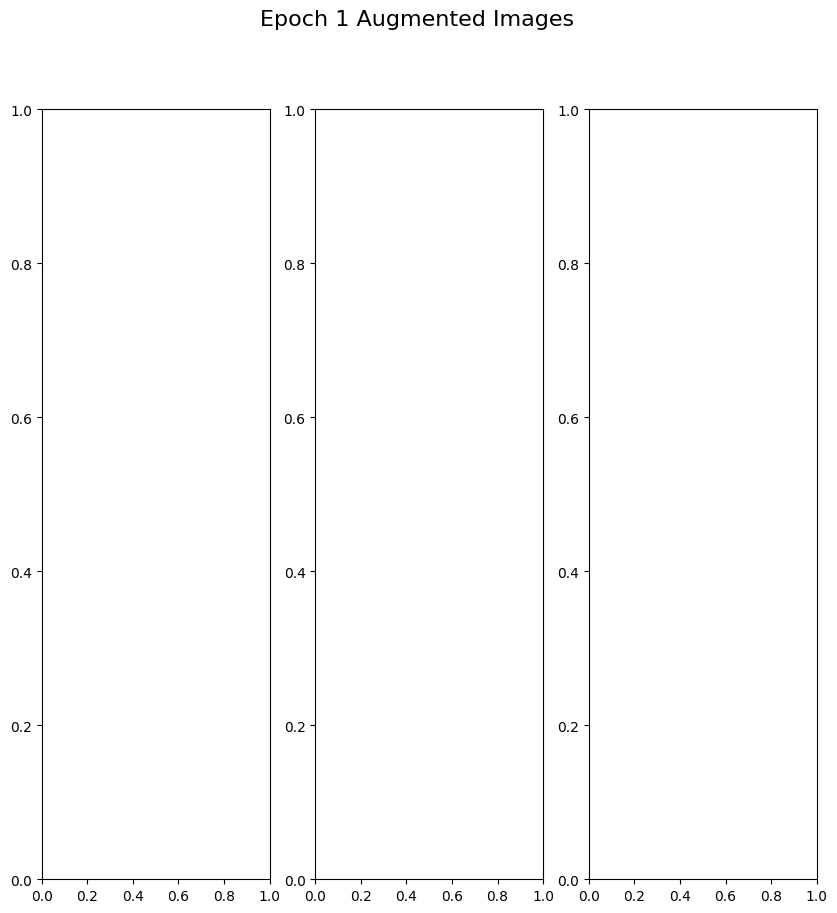

In [17]:
import matplotlib.pyplot as plt

def display_augmented_images(augmented_set, epoch):
    """Display augmented images in a grid using plt.imshow()."""
    num_images = len(augmented_set)
    cols = 3  # Number of images per row
    rows = (num_images // cols) + (num_images % cols > 0)  # Calculate rows based on number of images

    fig, axes = plt.subplots(rows, cols, figsize=(10, 10))
    fig.suptitle(f'Epoch {epoch+1} Augmented Images', fontsize=16)

    for idx, aug_img in enumerate(augmented_set):
        ax = axes[idx // cols, idx % cols]  # Get the subplot for the image
        ax.imshow(aug_img)
        ax.axis('off')  # Hide the axes for a cleaner look
        ax.set_title(f"Image {idx+1}")

    # Hide any extra subplots that might exist if the number of images isn't a multiple of the grid size
    for ax in axes.flatten()[num_images:]:
        ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to include the title
    plt.show()

# Example usage:
image_paths = [r'archive\valid\Car\10158.jpeg', r'archive\valid\Car\10164.jpeg', r'archive\valid\Car\10151.jpeg']
image_set = [Image.open(path) for path in image_paths]

auto_augmenter = AutoAugment()

# Simulate multiple epochs with different accuracies
for epoch in range(10):
    accuracy = random.uniform(0.7, 1.0)  # Example: Random accuracy for each epoch
    augmented_set = auto_augmenter.auto_augment(image_set, accuracy)

    # Display augmented images using plt.imshow()
    display_augmented_images(augmented_set, epoch)

    print(f"Epoch {epoch+1}, Accuracy: {accuracy:.2f}, Policy: {auto_augmenter.current_policy}")


C:\Users\M LAKSHMI NARASIMHA\AppData\Local\Temp\ipykernel_10852\1370216277.py:25: DeprecationWarning: Sampling from a set deprecated
since Python 3.9 and will be removed in a subsequent version.
  self.current_policy = random.sample(self.func.keys(), 3)  # Initial policy with 3 augmentations


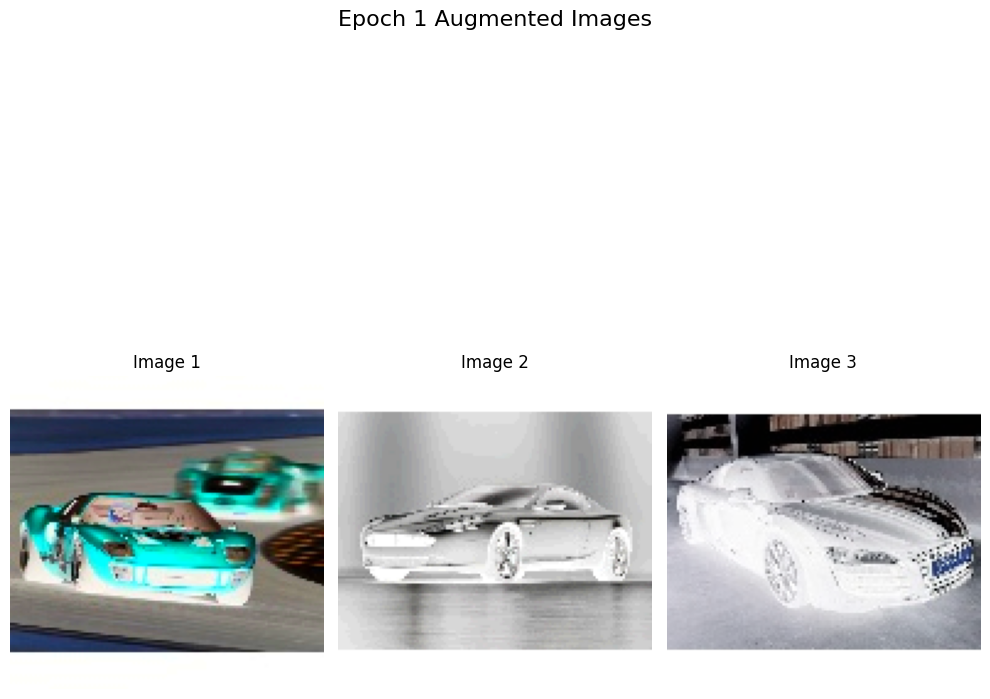

Epoch 1, Accuracy: 0.71, Policy: ['posterize', 'invert', 'color']


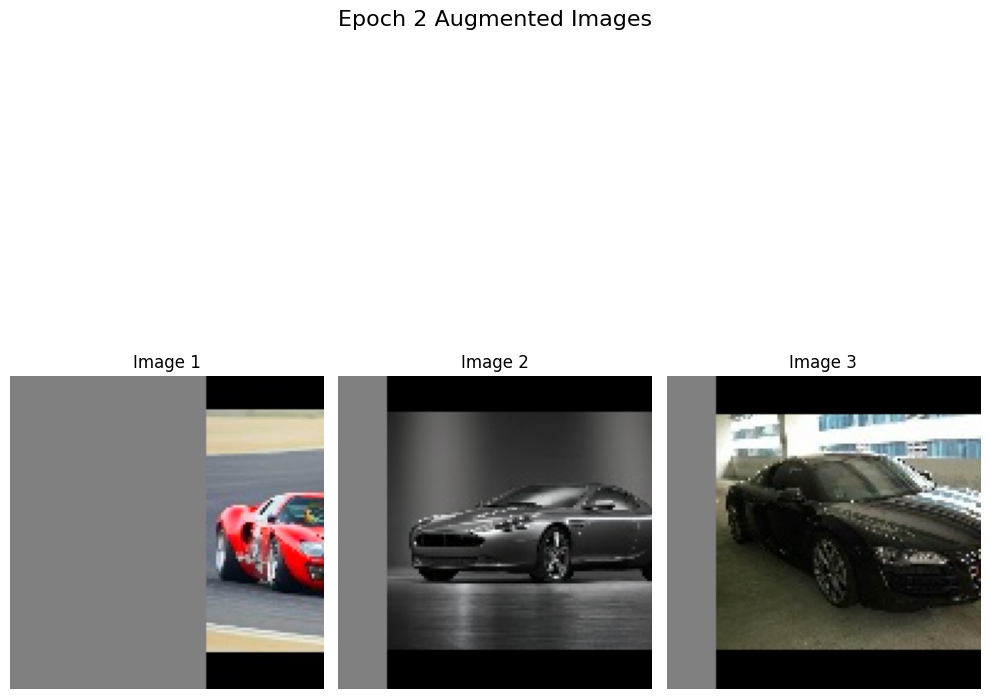

Epoch 2, Accuracy: 0.92, Policy: ['translateX', 'color', 'color']


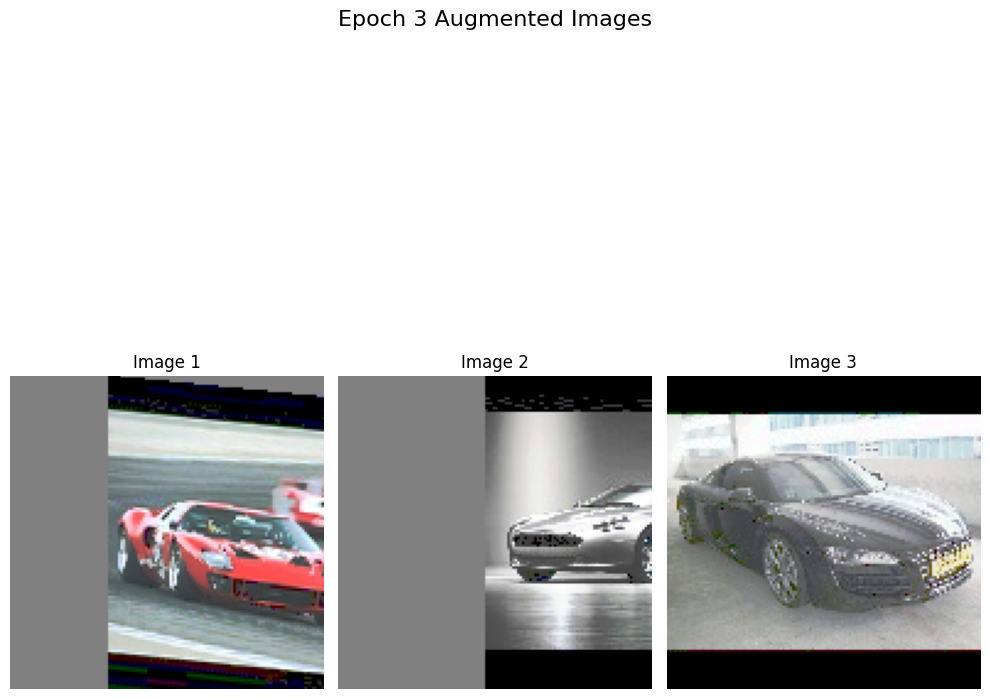

Epoch 3, Accuracy: 0.78, Policy: ['equalize', 'shearY', 'translateX']


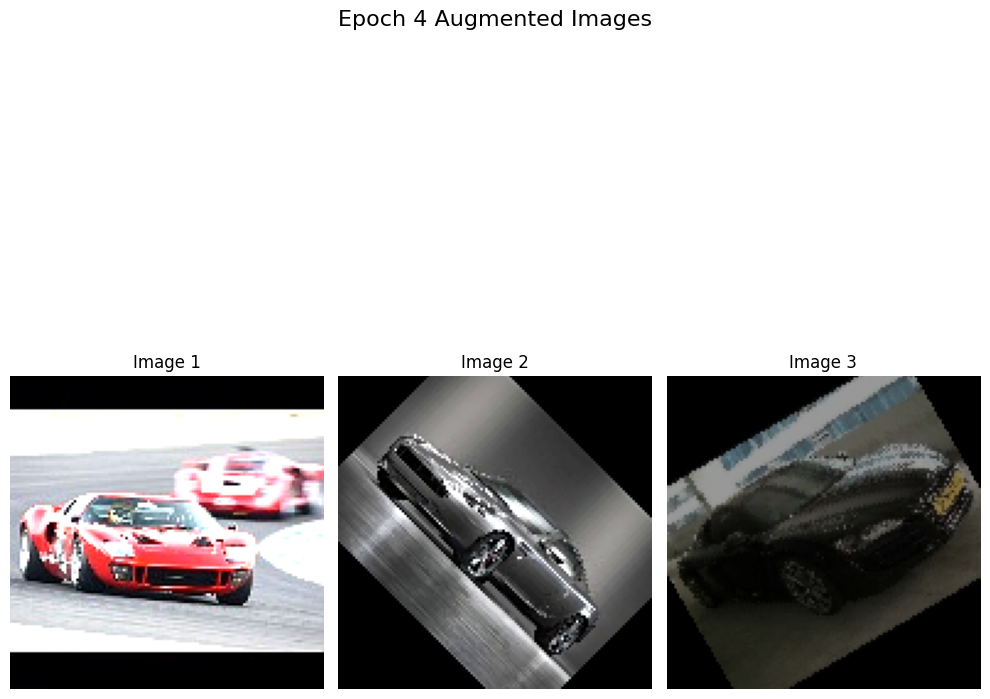

Epoch 4, Accuracy: 0.96, Policy: ['brightness', 'sharpness', 'rotate']


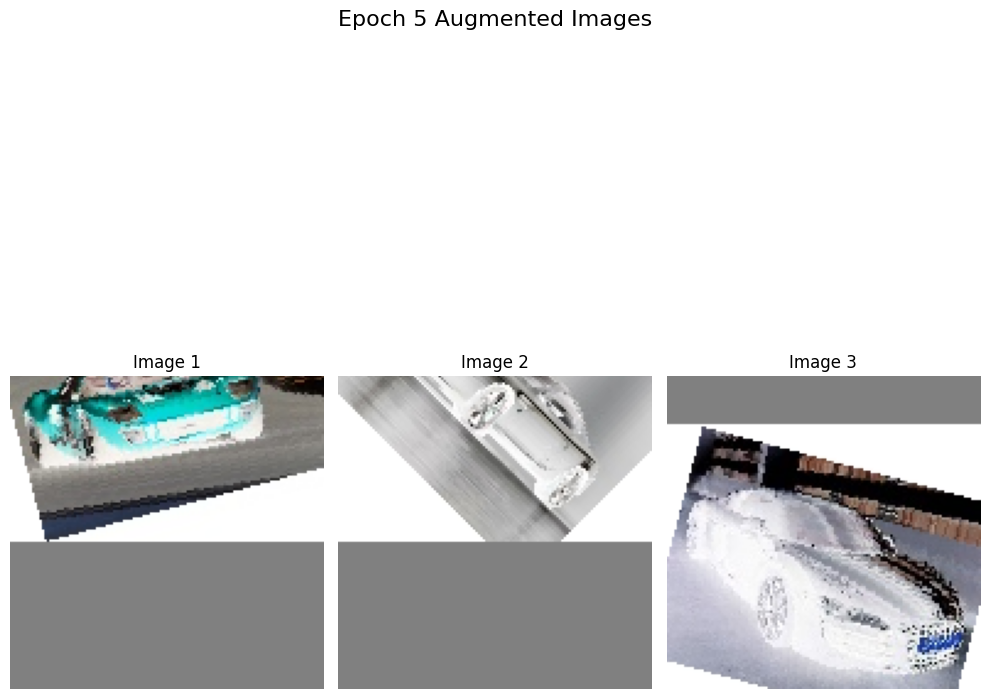

Epoch 5, Accuracy: 0.99, Policy: ['rotate', 'invert', 'translateY']


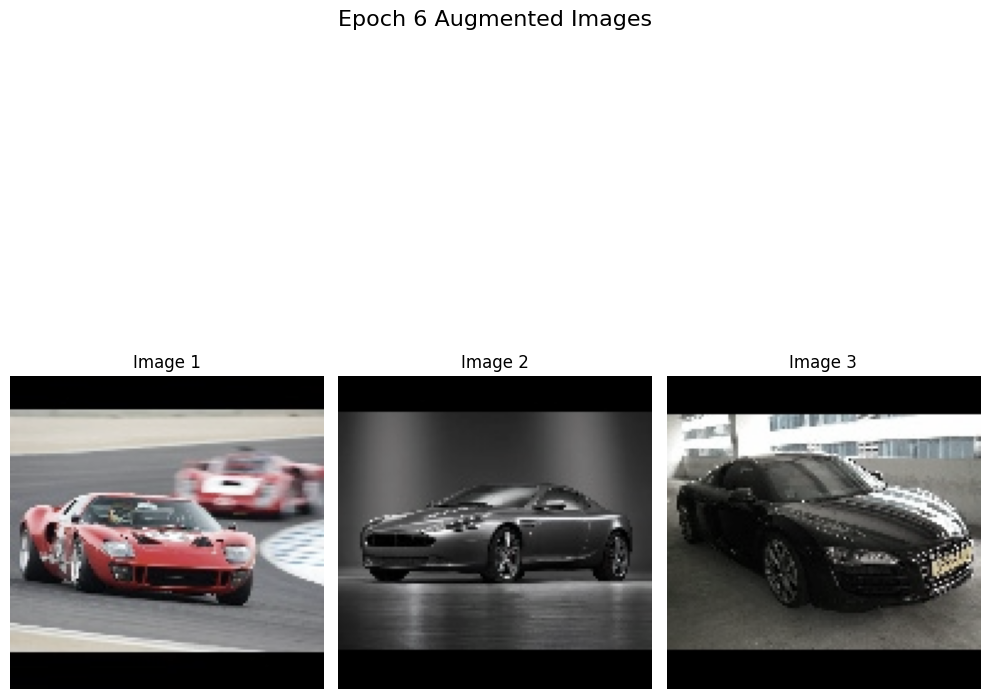

Epoch 6, Accuracy: 0.75, Policy: ['invert', 'color', 'invert']


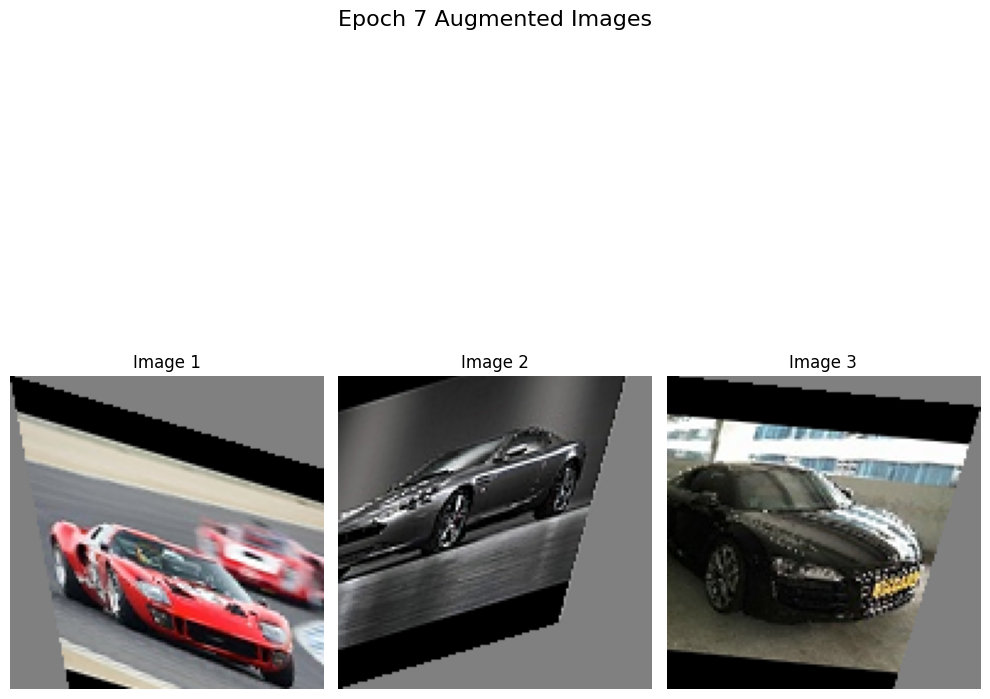

Epoch 7, Accuracy: 0.73, Policy: ['shearX', 'sharpness', 'shearY']


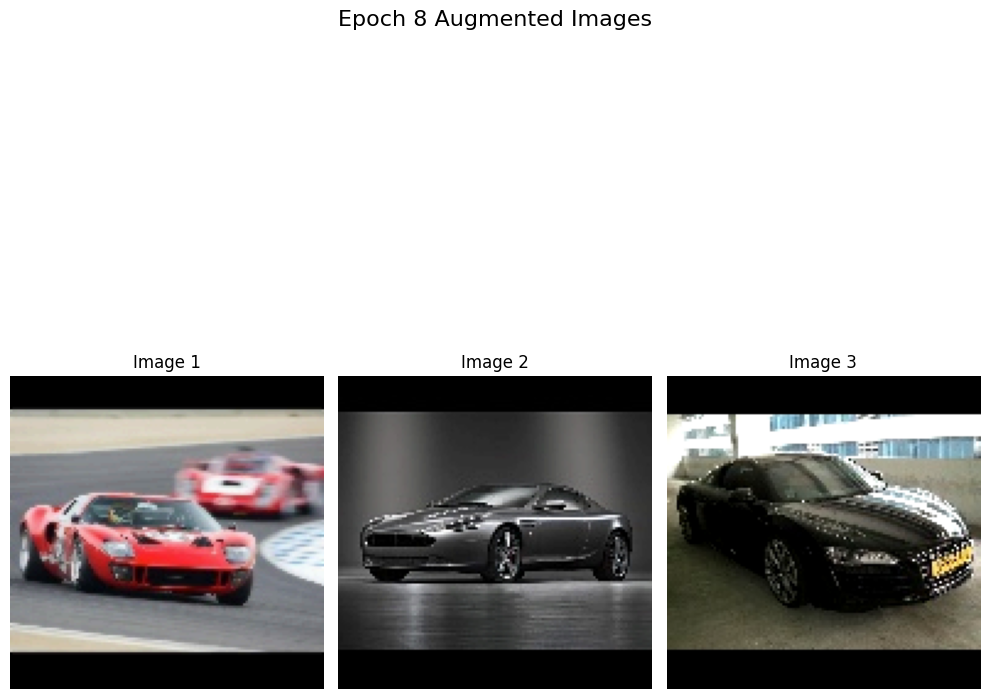

Epoch 8, Accuracy: 0.72, Policy: ['sharpness', 'contrast', 'autocontrast']


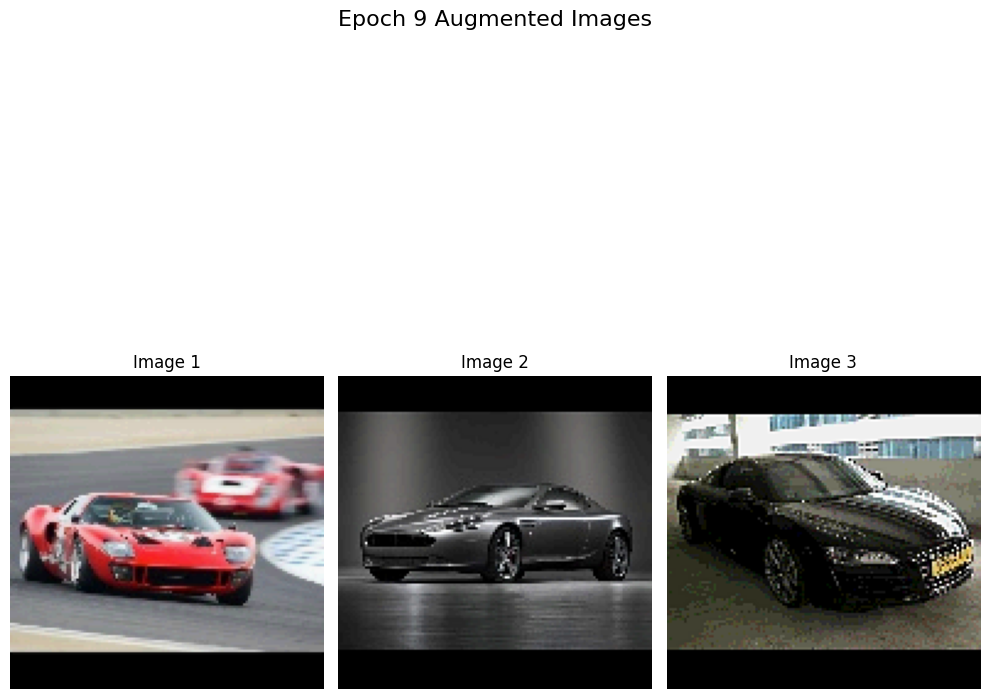

Epoch 9, Accuracy: 0.79, Policy: ['posterize', 'posterize', 'sharpness']


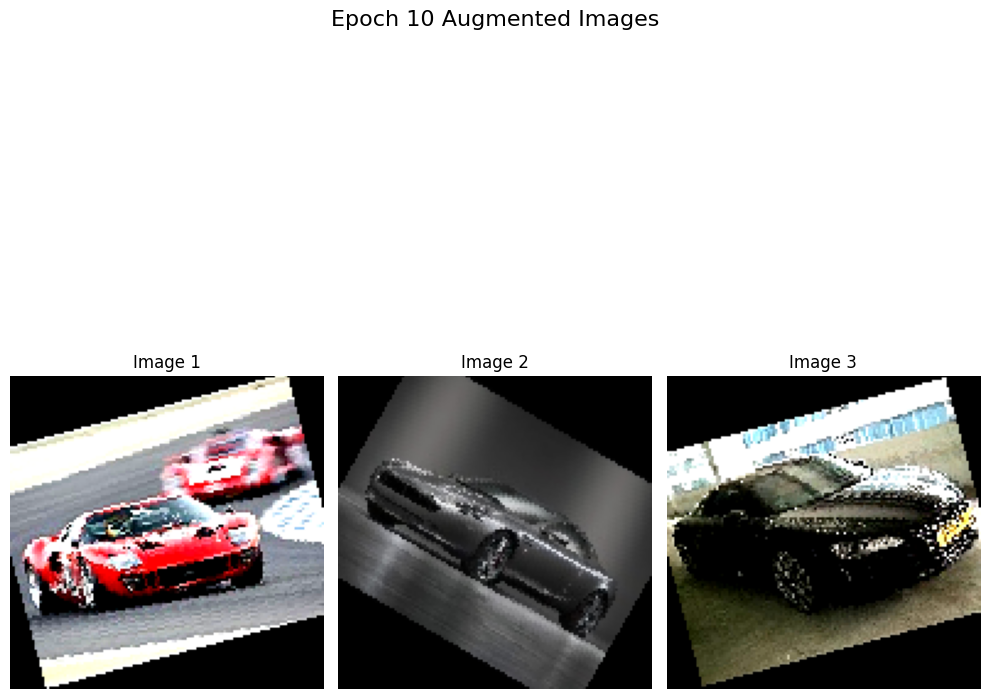

Epoch 10, Accuracy: 0.80, Policy: ['sharpness', 'rotate', 'contrast']


In [19]:
import matplotlib.pyplot as plt

def display_augmented_images(augmented_set, epoch):
    """Display augmented images in a grid using plt.imshow()."""
    num_images = len(augmented_set)
    cols = 3  # Number of images per row
    rows = (num_images // cols) + (num_images % cols > 0)  # Calculate rows based on number of images

    fig, axes = plt.subplots(rows, cols, figsize=(10, 10))
    fig.suptitle(f'Epoch {epoch+1} Augmented Images', fontsize=16)

    # If there's only one row, axes is a 1D array, we need to treat it accordingly
    if rows == 1:
        axes = np.array([axes])  # Wrap axes in an array to make it 2D for consistency

    # Loop through the augmented images and display them
    for idx, aug_img in enumerate(augmented_set):
        ax = axes[idx // cols, idx % cols]  # Get the correct subplot for the image
        ax.imshow(aug_img)
        ax.axis('off')  # Hide the axes for a cleaner look
        ax.set_title(f"Image {idx+1}")

    # Hide any extra subplots if there are more subplots than images
    if len(augmented_set) < rows * cols:
        for ax in axes.flatten()[num_images:]:
            ax.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Adjust layout to fit the title and images properly
    plt.show()

# Example usage:
image_paths = [r'archive\valid\Car\10158.jpeg', r'archive\valid\Car\10164.jpeg', r'archive\valid\Car\10151.jpeg']
image_set = [Image.open(path) for path in image_paths]

auto_augmenter = AutoAugment()

# Simulate multiple epochs with different accuracies
for epoch in range(10):
    accuracy = random.uniform(0.7, 1.0)  # Example: Random accuracy for each epoch
    augmented_set = auto_augmenter.auto_augment(image_set, accuracy)

    # Display augmented images using plt.imshow()
    display_augmented_images(augmented_set, epoch)

    print(f"Epoch {epoch+1}, Accuracy: {accuracy:.2f}, Policy: {auto_augmenter.current_policy}")
